# Validation: four stages, four questions

| Stage | Question |
|---|---|
| Unit | Does each rule do what it says? |
| Backtest | Is it more accurate on weeks it could not see? |
| Regression | Did a change touch anything it was not meant to? |
| Shadow | What would change if it shipped? |

Most arguments about a forecast turn out to be someone answering one of these questions with the evidence for another.

> Synthetic data. The numbers show that the harness works, not how accurate any real forecast is.

In [1]:
import sys
import unittest
from dataclasses import replace
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd

from forecast_review import pipeline, seasonality, synthetic, validation
from forecast_review.config import ADOPTION, DEFAULT
from forecast_review.plots import backtest_dots
from forecast_review.synthetic import AS_OF

weekly, plan = synthetic.generate(seed=7)

## 1. Unit: the operating rules, as tests

Each rule on the portfolio site is a test here: low in-stock is never cut, cuts and raises are capped, a raise needs a second signal, new items are protected, an unfinished week is never read, and the backtest cannot see the future.

In [2]:
suite = unittest.defaultTestLoader.discover(str(ROOT / "tests"), top_level_dir=str(ROOT))
result = unittest.TextTestRunner(stream=sys.stdout, verbosity=1).run(suite)

.

.

.

.

.

...

.

.

.

.

----------------------------------------------------------------------
Ran 20 tests in 0.262s

OK


## 2. Backtest: should each retailer follow the seasonal curve?

Three forecasts for the same eight weeks, from the same history, at four rolling origins: a naive forecast (next week equals last week), a flat recent average, and the same level re-shaped by the seasonal curve. The adoption rule was fixed in `config.py` before any result existed.

Adoption rule: seasonal must beat flat by at least 2.0 WMAPE points, on at least 8 items.


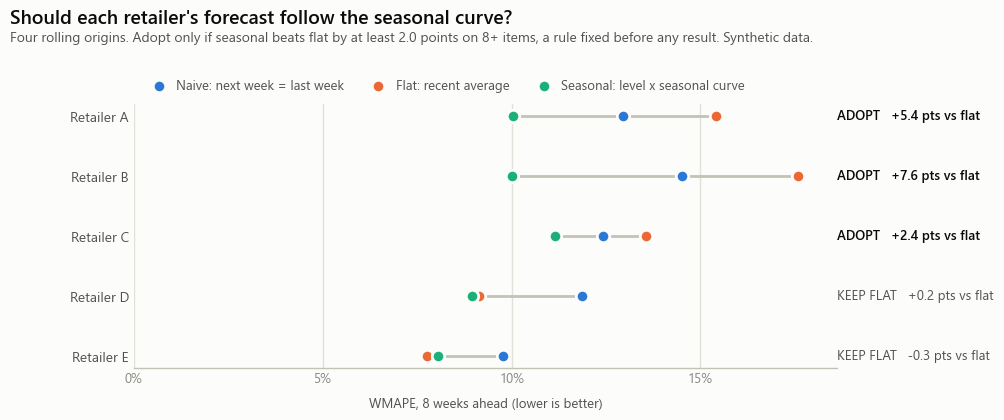

In [3]:
print(f"Adoption rule: seasonal must beat flat by at least {ADOPTION.min_gain_points:.1f} WMAPE points, "
      f"on at least {ADOPTION.min_items} items.")
table = validation.seasonal_backtest(weekly, AS_OF)
backtest_dots(table, path=ROOT / "images" / "backtest.png");

In [4]:
shown = table.copy()
for column in ("wmape_naive", "wmape_flat", "wmape_seasonal"):
    shown[column] = shown[column].map("{:.1%}".format)
shown["bias_seasonal"] = shown["bias_seasonal"].map("{:+.1%}".format)
for column in ("value_added_vs_naive", "gain_vs_flat"):
    shown[column] = shown[column].map("{:+.1f}".format)
shown

,retailer,items,wmape_naive,wmape_flat,wmape_seasonal,bias_seasonal,value_added_vs_naive,gain_vs_flat,decision
0,RETAILER_A,12,13.0%,15.4%,10.0%,+1.3%,+2.9,+5.4,ADOPT
1,RETAILER_B,12,14.5%,17.6%,10.0%,+0.7%,+4.5,+7.6,ADOPT
2,RETAILER_C,12,12.4%,13.6%,11.1%,-2.1%,+1.3,+2.4,ADOPT
3,RETAILER_D,11,11.9%,9.1%,9.0%,-0.4%,+2.9,+0.2,KEEP FLAT
4,RETAILER_E,12,9.8%,7.8%,8.1%,-0.4%,+1.7,-0.3,KEEP FLAT


The seasonal curve is adopted where seasonality is real (retailers A, B and C) and not where it is not (D and E). Every forecast is also scored against the naive one, so "better" always means better than doing nothing clever.

## 3. Regression: one change, identical data

Change under test: protect new items from cuts for their first weeks. Run the old and new rules on the same data. The only difference allowed is the one intended.

In [5]:
before = pipeline.review(weekly, plan, AS_OF, cfg=replace(DEFAULT, new_item_weeks=0))
after = pipeline.review(weekly, plan, AS_OF)
diff = validation.compare(before, after, labels=("before", "after"))
intended = diff.empty or (diff["weeks_of_history"] < DEFAULT.new_item_weeks).all()
print(f"{'PASS' if intended else 'FAIL'}: {len(diff)} item(s) changed.")
diff

PASS: 1 item(s) changed.


,retailer,sku,scenario,weeks_of_history,before,after
0,RETAILER_D,D-01,new_item,9,LOWER -20%,HOLD


## 4. Shadow: what the refuter is worth

Candidate: the same rules without the refuter, run beside the live review with nothing downstream connected.

In [6]:
live = pipeline.review(weekly, plan, AS_OF)
candidate = pipeline.review(weekly, plan, AS_OF, use_refuter=False)
validation.compare(live, candidate)

,retailer,sku,scenario,weeks_of_history,live,candidate
0,RETAILER_C,C-05,spike_baseline,104,HOLD,LOWER -20%


## 5. The forecast cannot see the period it forecasts

Multiply every sale after the forecast origin by ten. If the forecast moves, something in the pipeline is reading the future.

In [7]:
origin = AS_OF - pd.Timedelta(weeks=7)
tampered = weekly.copy()
tampered.loc[tampered["week"] >= origin, "pos_units"] *= 10

def forecast(data):
    history = validation.history_before(data, origin)
    curves = seasonality.segment_indices(history, DEFAULT.spike_ratio)
    item = history[history["sku"] == "A-01"]
    horizon = pd.Series(pd.date_range(origin, periods=8, freq="W-FRI"))
    return validation.forecast_pair(item, curves[("RETAILER_A", item["segment"].iloc[0])], horizon)

unchanged = all(np.allclose(a, b) for a, b in zip(forecast(weekly), forecast(tampered)))
print("Forecast unchanged by future data:", unchanged)

Forecast unchanged by future data: True


## Key findings

- All unit tests pass: the rules on the site are enforced in code, not just described.
- The pre-registered backtest adopts the seasonal curve for three retailers of five, exactly where seasonality exists.
- The rule change touched only the item it was meant to touch.
- Without the refuter, one stable item would have been cut on a promotion spike.
- Tampering with the future does not move the forecast.